# 07. Семинар. Метод kNN

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import load_digits, make_moons, make_circles, make_classification
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, mean_absolute_error,
                             median_absolute_error, r2_score)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
SEED = 42

## Часть 0. Разминка

### Задача 1

Предположим, мы решаем задачу классификации на три класса по двум признакам и используем метод k ближайших соседей с $k=3$ и манхэттенской метрикой. Мы имеем следующую обучающую выборку:

| № | Признак 1 | Признак 2 | Класс |
|---|-----------|-----------|-------|
| 1 | 1         | -1        | 1     |
| 2 | 2         | 2         | 1     |
| 3 | 3         | 2         | 2     |
| 4 | 1         | 0         | 3     |
| 5 | 2         | -2        | 3     |

Каковы будут предсказания для объекта $x=(2, -1)$?

<details>
<summary><b>Показать ответ</b></summary>

Алгоритм предсказания kNN для задачи классификации:

1. Вычислить расстояние от каждого объекта обучающей выборки до тестового объекта.
2. Найти $k$ объектов обучающей выборки (соседей) с наименьшим расстоянием до тестового объекта.
3. Вернуть наиболее часто встречающийся класс среди $k$ соседей.

Расстояние от первого объекта обучения до $x$ (манхэттенская метрика): $|1-2| + |-1-(-1)| = 1$. Аналогично для объектов 2-5: 3, 4, 2, 1.

Три ближайших объекта: номера 1 и 5 (расстояние 1 у обоих) и номер 4 (расстояние 2). Их классы: 1, 3, 3. Чаще всего встречается класс 3, поэтому предсказываем **3**.

</details>

### Задача 2

Теперь решаем задачу регрессии по двум признакам, снова $k=3$ и манхэттенская метрика. Обучающая выборка:

| № | Признак 1 | Признак 2 | Ответ |
|---|-----------|-----------|-------|
| 1 | 1         | -1        | 3.5   |
| 2 | 2         | 2         | 2.3   |
| 3 | 3         | 2         | 1.7   |
| 4 | 1         | 0         | -0.4  |
| 5 | 2         | -2        | 0.1   |

Каковы будут предсказания для объекта $x=(2, -1)$?

<details>
<summary><b>Показать ответ</b></summary>

Предсказание kNN для регрессии отличается от классификации только последним шагом: вместо наиболее частого класса берем **среднее** ответов соседей. Признаки те же, что в задаче 1, поэтому соседи те же: объекты 1, 4 и 5. Их ответы: 3.5, -0.4, 0.1. Среднее:

$$\frac{3.5 - 0.4 + 0.1}{3} = \frac{3.2}{3} \approx 1.07.$$

Предсказываем **1.07**.

</details>

### Вопрос: каковы параметры и гиперпараметры метода kNN?

<details>
<summary><b>Показать ответ</b></summary>

Параметры - величины, которые настраиваются в процессе обучения по обучающей выборке. В kNN обучения как такового нет, это простой эвристический алгоритм. Можно считать, что параметры kNN - это сама обучающая выборка (в другой трактовке у метода параметров нет).

Гиперпараметры - величины, которые мы задаем до обучения и которые не настраиваются по обучающей выборке. Главные гиперпараметры kNN: число соседей $k$ и метрика. Еще два: способ взвешивания соседей (равные веса или обратно пропорциональные расстоянию) и, в случае метрики Минковского, показатель степени $p$. Разные комбинации дают совсем разное качество. Гиперпараметры подбирают по валидационной выборке или кросс-валидацией.

</details>

### Вопрос: как меняется качество kNN при увеличении $k$?

<details>
<summary><b>Показать ответ</b></summary>

При $k=1$ вокруг каждого объекта обучения создается область его класса. Если в «большую» область одного класса случайно попал шумовой объект другого класса, вокруг него появится «остров» чужого класса. Это нелогично и говорит о переобучении.

Если $k$ равно числу объектов в выборке, для всех объектов предсказывается одно и то же (самый частый класс), качество низкое.

Значит, качество сначала растет, потом падает, оптимум где-то посередине. Сами увидим это на картинках в части 1.

</details>

### Вопрос: почему при использовании kNN важно нормировать данные?

<details>
<summary><b>Показать ответ</b></summary>

Возьмем манхэттенскую метрику. Если один признак имеет масштаб порядка 1000, а другой порядка 1, то при сложении модулей разностей второй признак почти не влияет на ответ: все решает первый. Если признаки привести к одной шкале (например, стандартизовать), вклад признаков в расстояние становится сопоставимым. Дальше в части 4 мы посмотрим на это на реальных данных.

</details>

## Часть 1. kNN своими руками

Алгоритм настолько простой, что его можно написать на numpy за несколько строк. Заодно убедимся, что мы правильно понимаем, что делает `KNeighborsClassifier`.

In [2]:
def knn_predict(X_train, y_train, x, k=3, p=1, task="classification"):
    """Предсказание kNN для одного объекта x. p=1 - манхэттенская, p=2 - евклидова метрика."""
    # шаг 1: расстояния от x до всех объектов обучения
    dist = (np.abs(X_train - x) ** p).sum(axis=1) ** (1 / p)
    # шаг 2: индексы k ближайших
    nearest = np.argsort(dist)[:k]
    # шаг 3: голосование (классификация) или усреднение (регрессия)
    if task == "classification":
        values, counts = np.unique(y_train[nearest], return_counts=True)
        return values[np.argmax(counts)]
    return y_train[nearest].mean()

Проверим на задачах 1 и 3. Ответы должны совпасть с тем, что мы получили на бумаге.

In [3]:
X1 = np.array([[1, -1], [2, 2], [3, 2], [1, 0], [2, -2]])
y_cls = np.array([1, 1, 2, 3, 3])
y_reg = np.array([3.5, 2.3, 1.7, -0.4, 0.1])
x_new = np.array([2, -1])

print("Задача 1 (класс):   ", knn_predict(X1, y_cls, x_new, k=3, p=1))
print("Задача 2 (значение):", round(knn_predict(X1, y_reg, x_new, k=3, p=1, task="regression"), 3))

Задача 1 (класс):    3
Задача 2 (значение): 1.067


Теперь сравним нашу функцию с sklearn на «настоящих» данных: двух полумесяцах с шумом. Если мы все сделали верно, предсказания совпадут на всех объектах.

In [4]:
X_m, y_m = make_moons(n_samples=300, noise=0.35, random_state=SEED)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(X_m, y_m, test_size=0.3, stratify=y_m, random_state=SEED)

own = np.array([knn_predict(Xm_tr, ym_tr, x, k=5, p=2) for x in Xm_te])
sk = KNeighborsClassifier(n_neighbors=5, p=2).fit(Xm_tr, ym_tr).predict(Xm_te)

print("Доля совпавших предсказаний:", np.mean(own == sk))

Доля совпавших предсказаний: 1.0


### Что происходит при разных $k$

Нарисуем границу классов для $k = 1, 5, 25$ и для $k$, равного размеру обучающей выборки. В заголовках указана точность на обучении и на тесте.

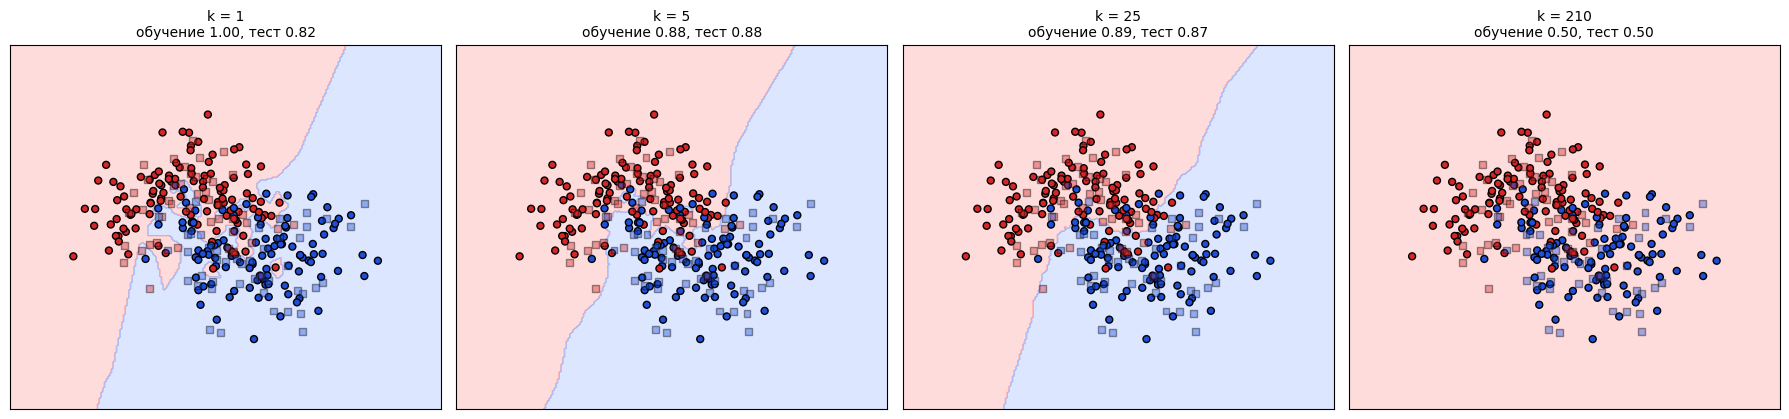

In [6]:
def plot_boundary(model, X, y, X_te, y_te, ax, title):
    DecisionBoundaryDisplay.from_estimator(
        model, X, ax=ax, alpha=0.35, response_method="predict", grid_resolution=250,
        cmap=ListedColormap(["#ff9d9d", "#9db8ff"]))
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(["#d62728", "#1f4fd8"]), edgecolors="k", s=25)
    ax.scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap=ListedColormap(["#d62728", "#1f4fd8"]),
               edgecolors="k", s=25, alpha=0.4, marker="s")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

ks = [1, 5, 25, len(Xm_tr)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, k in zip(axes, ks):
    m = KNeighborsClassifier(n_neighbors=k).fit(Xm_tr, ym_tr)
    plot_boundary(m, Xm_tr, ym_tr, Xm_te, ym_te, ax,
                  f"k = {k}\nобучение {m.score(Xm_tr, ym_tr):.2f}, тест {m.score(Xm_te, ym_te):.2f}")
plt.tight_layout()
plt.show();

Круги - обучающие объекты, квадраты - тестовые (полупрозрачные).

**Вопрос.** Опишите, что вы видите при $k=1$ и при $k=N$. При каком $k$ граница выглядит наиболее разумно?

<details>
<summary><b>Показать ответ</b></summary>

При $k=1$ граница очень «рваная», вокруг отдельных шумовых точек появляются острова чужого цвета, на обучении точность 1.00 (каждый объект сам себе ближайший), а на тесте заметно ниже: переобучение. При $k=N$ вся плоскость одного цвета (побеждает самый частый класс), модель вообще не использует признаки: недообучение. Разумная граница получается при умеренных $k$ (в районе 15-30 на этих данных).

</details>

Одна картинка и одно разбиение - слабое основание для выводов: на 90 тестовых объектах точность «скачет» от случайности. Усредним по 30 случайным разбиениям и нарисуем кривую качества от $k$.

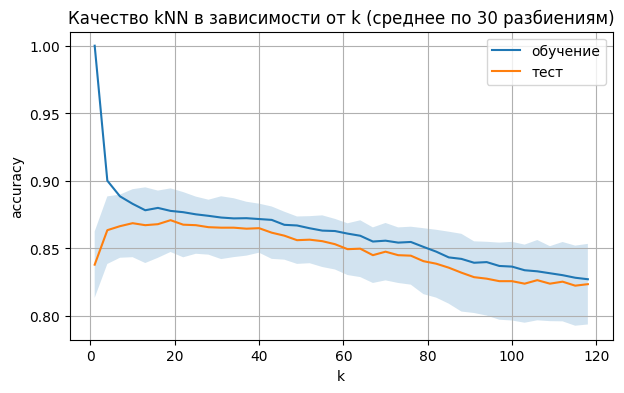

Лучший k по среднему на тесте: 19 | accuracy: 0.871


In [7]:
ks_curve = list(range(1, 120, 3))
tr_acc, te_acc = [], []
for seed in range(30):
    a, b, c, d = train_test_split(X_m, y_m, test_size=0.3, stratify=y_m, random_state=seed)
    tr_row, te_row = [], []
    for k in ks_curve:
        m = KNeighborsClassifier(n_neighbors=k).fit(a, c)
        tr_row.append(m.score(a, c)); te_row.append(m.score(b, d))
    tr_acc.append(tr_row); te_acc.append(te_row)
tr_acc, te_acc = np.array(tr_acc), np.array(te_acc)

plt.plot(ks_curve, tr_acc.mean(0), label="обучение")
plt.plot(ks_curve, te_acc.mean(0), label="тест")
plt.fill_between(ks_curve, te_acc.mean(0) - te_acc.std(0), te_acc.mean(0) + te_acc.std(0), alpha=0.2)
plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend()
plt.title("Качество kNN в зависимости от k (среднее по 30 разбиениям)")
plt.show();
best_k = ks_curve[int(np.argmax(te_acc.mean(0)))]
print("Лучший k по среднему на тесте:", best_k, "| accuracy:", round(te_acc.mean(0).max(), 3))

## Часть 2. Распознавание рукописных цифр

Датасет `digits` из sklearn: 1797 изображений цифр 8x8 пикселей. Каждый пиксель - яркость от 0 (черный) до 16 (белый), то есть объект описывается 64 признаками. Задача: по картинке определить цифру от 0 до 9. Это классика, на которой kNN работает очень хорошо.

Объекты x признаки: (1797, 64) | классов: 10
Доли классов: [0.099 0.101 0.098 0.102 0.101 0.101 0.101 0.1   0.097 0.1  ]


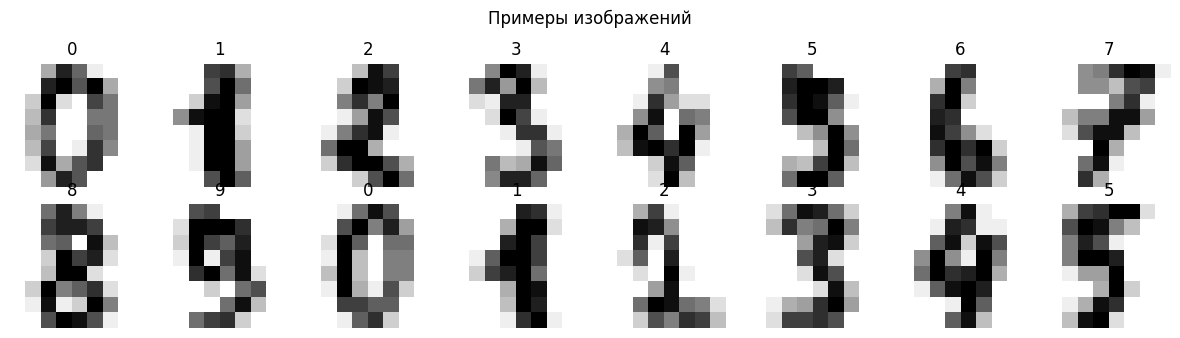

In [8]:
data = load_digits()
X_img, y = data.images, data.target
X = X_img.reshape(len(X_img), -1)           # картинку 8x8 вытягиваем в вектор из 64 признаков
print("Объекты x признаки:", X.shape, "| классов:", len(np.unique(y)))
print("Доли классов:", np.round(np.bincount(y) / len(y), 3))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_img[i], cmap="gray_r"); ax.set_title(f"{y[i]}"); ax.axis("off")
plt.suptitle("Примеры изображений"); plt.tight_layout(); plt.show();

Разобьем данные на обучающую и тестовую части: 70% / 30%. Параметр `stratify=y` сохраняет доли классов в обеих частях, а `random_state` делает разбиение воспроизводимым. **Тест мы откроем только один раз, в конце.** Все решения (какой $k$, какая метрика) принимаем по обучающей части с помощью кросс-валидации.

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)

base = KNeighborsClassifier(n_neighbors=3).fit(X_tr, y_tr)
print(f"accuracy на обучении: {base.score(X_tr, y_tr):.3f}")

accuracy на обучении: 0.995


### Как выбирать $k$: один валидационный набор или кросс-валидация

Самый простой способ - выделить из обучающей части валидационную выборку и перебрать $k$. Но результат зависит от того, какие именно объекты попали в валидацию. Повторим эту процедуру 10 раз с разным разбиением и посмотрим, какой $k$ каждый раз объявляется лучшим.

In [10]:
for seed in range(10):
    a, b, c, d = train_test_split(X_tr, y_tr, test_size=0.4, stratify=y_tr, random_state=seed)
    scores = {k: KNeighborsClassifier(n_neighbors=k).fit(a, c).score(b, d) for k in range(1, 16)}
    k_star = max(scores, key=scores.get)
    print(f"разбиение {seed}: лучший k = {k_star:2d}, accuracy на валидации = {scores[k_star]:.3f}")

разбиение 0: лучший k =  3, accuracy на валидации = 0.982
разбиение 1: лучший k =  3, accuracy на валидации = 0.980
разбиение 2: лучший k =  1, accuracy на валидации = 0.980
разбиение 3: лучший k =  3, accuracy на валидации = 0.982
разбиение 4: лучший k =  1, accuracy на валидации = 0.982
разбиение 5: лучший k =  1, accuracy на валидации = 0.974
разбиение 6: лучший k =  5, accuracy на валидации = 0.984
разбиение 7: лучший k =  3, accuracy на валидации = 0.982
разбиение 8: лучший k =  1, accuracy на валидации = 0.980
разбиение 9: лучший k =  3, accuracy на валидации = 0.984


**Вопрос.** Что видно? Можно ли доверять одному такому разбиению?

<details>
<summary><b>Показать ответ</b></summary>

Лучший $k$ меняется от разбиения к разбиению, а accuracy на валидации «лучшего» $k$ слегка завышена: мы взяли максимум из 15 шумных чисел. Один валидационный набор - случайность. Надежнее **кросс-валидация**: делим обучающую часть на 5 блоков, по очереди используем каждый как валидацию, а качество усредняем. Заодно получаем разброс (стандартное отклонение), по которому видно, какие различия между $k$ реальны, а какие нет.

</details>

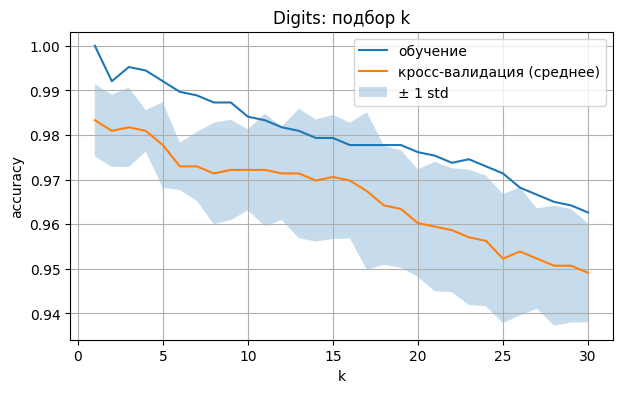

лучший k по CV: 1, accuracy 0.9833 ± 0.0081


In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ks = list(range(1, 31))
cv_mean, cv_std, train_acc = [], [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    s = cross_val_score(m, X_tr, y_tr, cv=cv)
    cv_mean.append(s.mean()); cv_std.append(s.std())
    train_acc.append(m.fit(X_tr, y_tr).score(X_tr, y_tr))
cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)

plt.plot(ks, train_acc, label="обучение")
plt.plot(ks, cv_mean, label="кросс-валидация (среднее)")
plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, alpha=0.25, label="± 1 std")
plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend(); plt.title("Digits: подбор k")
plt.show();
k_cv = ks[int(np.argmax(cv_mean))]
print(f"лучший k по CV: {k_cv}, accuracy {cv_mean.max():.4f} ± {cv_std[k_cv - 1]:.4f}")

**Вопросы.** (1) Почему на обучении при $k=1$ точность ровно 1.0? (2) Видна ли здесь «горка» качества, как на полумесяцах? (3) Чем $k=1$ реально отличается от $k=3$ или $k=5$?

<details>
<summary><b>Показать ответ</b></summary>

(1) Каждый объект обучения - ближайший сам к себе (расстояние 0), поэтому при $k=1$ он всегда предсказывает собственный класс. Качество на обучении при подборе $k$ бесполезно, поэтому нужна валидация.

(2) На цифрах «горки» почти нет: данные чистые, классы хорошо разделены, и качество плавно убывает с ростом $k$. Шумовых объектов мало, поэтому «острова» при малых $k$ почти не мешают. На зашумленных данных (как полумесяцы) оптимум был бы в середине.

(3) Различие между малыми $k$ меньше разброса между блоками кросс-валидации (серая полоса). То есть выбирать между $k=1$, $3$ и $5$ по точности на цифрах бессмысленно: все три практически эквивалентны. Разумно взять небольшое нечетное $k$.

</details>

### Метрики и веса соседей

На лекции были метрики евклидова, манхэттенская, косинусная. Сравним их при $k=3$ и $k=5$, а заодно проверим взвешивание по расстоянию. Для каждой комбинации - кросс-валидация на обучающей части.

In [12]:
rows = []
for metric in ["euclidean", "manhattan", "chebyshev", "cosine"]:
    for weights in ["uniform", "distance"]:
        for k in [3, 5]:
            m = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights)
            s = cross_val_score(m, X_tr, y_tr, cv=cv)
            rows.append({"metric": metric, "weights": weights, "k": k, "cv_acc": s.mean(), "std": s.std()})
res = pd.DataFrame(rows).pivot_table(index=["metric", "weights"], columns="k", values="cv_acc")
res.round(4)

k                        3       5
metric    weights                 
chebyshev distance  0.9682  0.9698
          uniform   0.9650  0.9698
cosine    distance  0.9849  0.9825
          uniform   0.9849  0.9801
euclidean distance  0.9817  0.9817
          uniform   0.9817  0.9777
manhattan distance  0.9754  0.9769
          uniform   0.9746  0.9730

**Вопрос.** Какая метрика лучше? Все ли различия значимы? Почему чебышевское расстояние (максимум модулей разностей по признакам) проигрывает?

<details>
<summary><b>Показать ответ</b></summary>

Косинусная и евклидова метрики лучше всего (около 98-98.5%), манхэттенская чуть хуже (около 97.5%), чебышевская заметно хуже (96.5-97%). Различия между первыми тремя сопоставимы с разбросом кросс-валидации (около 1 п.п.), поэтому уверенно выбрать «лучшую» среди них нельзя. Взвешивание по расстоянию почти ничего не меняет. Чебышевское расстояние смотрит только на **один** самый различающийся пиксель и игнорирует остальные 63, поэтому теряет много информации о форме цифры.

Урок: метрику нужно подбирать, но на каждой задаче эффект разный. Дальше, на квартирах, веса и метрика дадут заметно больший прирост.

</details>

### Подбор гиперпараметров целиком: `GridSearchCV`

In [13]:
param_grid = {
    "n_neighbors": list(range(1, 16)),
    "metric": ["euclidean", "manhattan", "cosine"],
    "weights": ["uniform", "distance"],
}
gs = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
print("Лучшие параметры:", gs.best_params_)
print(f"CV accuracy: {gs.best_score_:.4f}")

best = gs.best_estimator_
print(f"Тест (первый и единственный раз): {best.score(X_te, y_te):.4f}")
print(f"Для сравнения, kNN с k=3 по умолчанию: {base.score(X_te, y_te):.4f}")

Лучшие параметры: {'metric': 'cosine', 'n_neighbors': 3, 'weights': 'distance'}
CV accuracy: 0.9849
Тест (первый и единственный раз): 0.9870
Для сравнения, kNN с k=3 по умолчанию: 0.9870


**Вопрос.** Стоило ли тратить время на подбор?

<details>
<summary><b>Показать ответ</b></summary>

На тесте подобранная модель и kNN с $k=3$ по умолчанию дали одну и ту же точность: на этих данных выигрыш от подбора нулевой (на кросс-валидации он тоже невелик, около 0.3 п.п.). Тестовая выборка содержит всего 540 объектов, одна ошибка - это 0.19 п.п., поэтому мелкие различия вообще нельзя считать реальными. Вывод: kNN на цифрах работает хорошо «из коробки»; подбор гиперпараметров делать нужно, но не стоит ждать от него чудес. Тест нельзя использовать для выбора модели: мы открыли его один раз.

</details>

### Где ошибается модель

Матрица ошибок показывает, какие цифры путаются между собой.

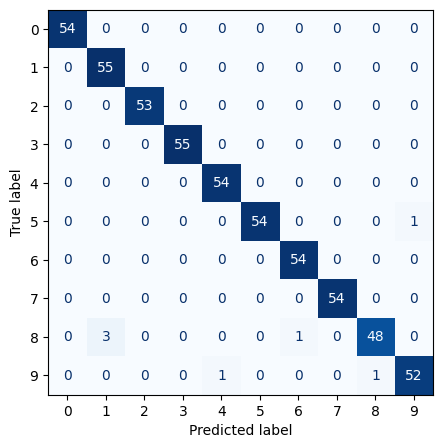

Ошибки (истина -> предсказано: сколько раз):
  8 -> 1: 3
  5 -> 9: 1
  8 -> 6: 1
  9 -> 4: 1
  9 -> 8: 1


In [14]:
y_pred = best.predict(X_te)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, ax=ax, colorbar=False, cmap="Blues")
ax.grid(False)
plt.show();

cm = confusion_matrix(y_te, y_pred)
np.fill_diagonal(cm, 0)
pairs = [(int(i), int(j), int(cm[i, j])) for i, j in zip(*np.nonzero(cm))]
print("Ошибки (истина -> предсказано: сколько раз):")
for i, j, c in sorted(pairs, key=lambda t: -t[2]):
    print(f"  {i} -> {j}: {c}")

### Почему ошиблись: смотрим на соседей

Главное достоинство kNN - **интерпретируемость**: на любое предсказание можно посмотреть глазами, потому что оно целиком определяется конкретными объектами обучения. Для каждой ошибки покажем сам объект и трех его ближайших соседей (с метками и расстояниями; метрика в лучшей модели косинусная, поэтому расстояния малы).

Число ошибок: 7 из 540


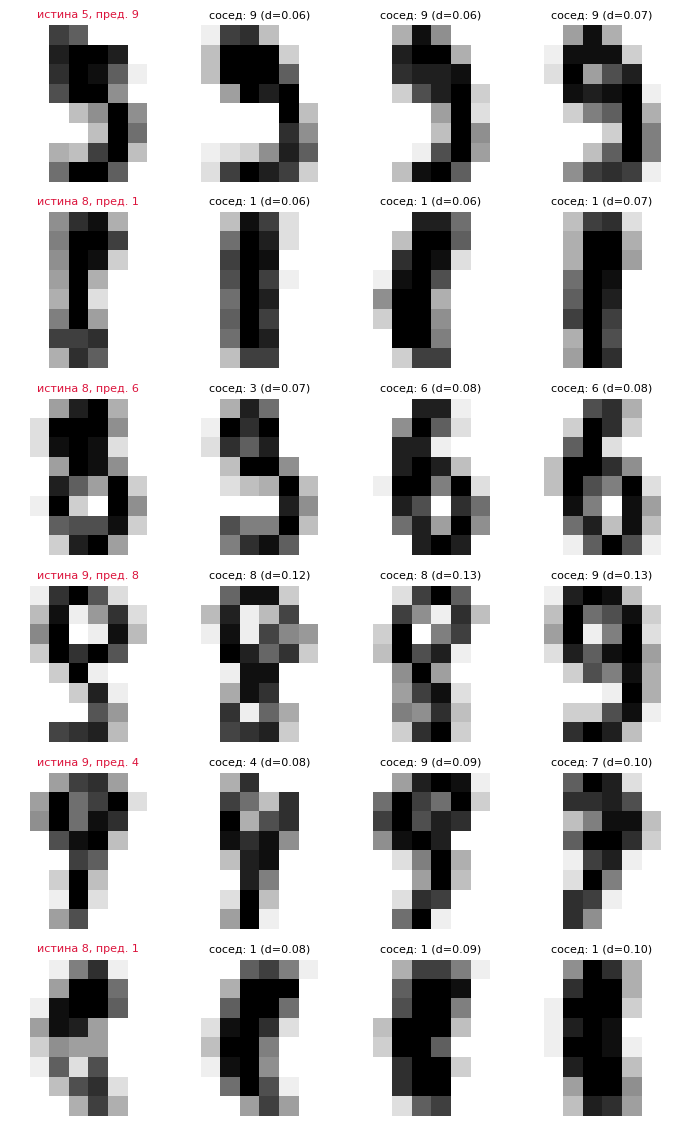

In [15]:
wrong = np.where(y_pred != y_te)[0]
print("Число ошибок:", len(wrong), "из", len(y_te))

show = wrong[:6]
dist, ind = best.kneighbors(X_te[show], n_neighbors=3)

fig, axes = plt.subplots(len(show), 4, figsize=(7, 1.9 * len(show)))
for r, i in enumerate(show):
    axes[r, 0].imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    axes[r, 0].set_title(f"истина {y_te[i]}, пред. {y_pred[i]}", fontsize=8, color="crimson")
    for c in range(3):
        j = ind[r, c]
        axes[r, c + 1].imshow(X_tr[j].reshape(8, 8), cmap="gray_r")
        axes[r, c + 1].set_title(f"сосед: {y_tr[j]} (d={dist[r, c]:.2f})", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show();

**Вопрос.** Что общего у большинства ошибок?

<details>
<summary><b>Показать ответ</b></summary>

Типичные ошибки: цифра нарисована небрежно или нетипично, и ближайшие по пикселям объекты принадлежат другому классу. Ряд картинок и человеку трудно уверенно прочитать на разрешении 8x8. Из-за интерпретируемости kNN мы сразу видим причину: не «нейросеть что-то решила», а «этот объект больше всего похож на вот эти три картинки». Для аудита и поддержки пользователей это очень ценно.

</details>

### Уверенность предсказания: пусть модель иногда отказывается

У kNN есть естественная оценка уверенности: доля соседей, проголосовавших за выбранный класс. Если соседи единогласны, предсказание надежнее. Возьмем $k=7$ и посмотрим на точность в зависимости от согласованности соседей.

In [16]:
knn7 = KNeighborsClassifier(n_neighbors=7).fit(X_tr, y_tr)
proba = knn7.predict_proba(X_te).max(axis=1)      # доля соседей за выбранный класс
pred7 = knn7.predict(X_te)

unanimous = proba == 1.0
print(f"Единогласно ({unanimous.mean():.1%} объектов): accuracy = {np.mean(pred7[unanimous] == y_te[unanimous]):.3f}")
print(f"Есть разногласия ({(~unanimous).mean():.1%} объектов): accuracy = {np.mean(pred7[~unanimous] == y_te[~unanimous]):.3f}")

Единогласно (89.3% объектов): accuracy = 0.996
Есть разногласия (10.7% объектов): accuracy = 0.879


Практический вывод: объекты с разногласием можно отправлять на ручную проверку, а остальные обрабатывать автоматически. Так работают многие реальные системы распознавания.

## Часть 3. Проклятие размерности

У kNN нет встроенного отбора признаков: все признаки одинаково участвуют в расстоянии. Что произойдет, если к 64 полезным признакам добавить бесполезные? Добавим к каждой картинке $K$ столбцов случайного шума той же яркости (от 0 до 16) и посмотрим на точность.

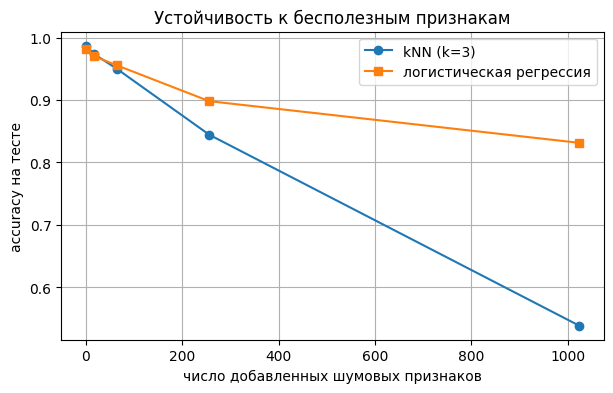

,шумовых признаков,kNN,лог. регрессия
0,0,0.987,0.981
1,16,0.974,0.970
2,64,0.950,0.956
3,256,0.844,0.898
4,1024,0.539,0.831


In [18]:
rng = np.random.RandomState(SEED)
noise_levels = [0, 16, 64, 256, 1024]
knn_acc, lr_acc = [], []
for K in noise_levels:
    Xa = np.hstack([X_tr, rng.uniform(0, 16, (len(X_tr), K))])
    Xb = np.hstack([X_te, rng.uniform(0, 16, (len(X_te), K))])
    knn_acc.append(KNeighborsClassifier(n_neighbors=3).fit(Xa, y_tr).score(Xb, y_te))
    lr_acc.append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)).fit(Xa, y_tr).score(Xb, y_te))

plt.plot(noise_levels, knn_acc, marker="o", label="kNN (k=3)")
plt.plot(noise_levels, lr_acc, marker="s", label="логистическая регрессия")
plt.xlabel("число добавленных шумовых признаков"); plt.ylabel("accuracy на тесте"); plt.legend()
plt.title("Устойчивость к бесполезным признакам")
plt.show();
pd.DataFrame({"шумовых признаков": noise_levels, "kNN": np.round(knn_acc, 3), "лог. регрессия": np.round(lr_acc, 3)})

**Вопрос.** Почему kNN так сильно проседает? Почему логистическая регрессия страдает меньше?

<details>
<summary><b>Показать ответ</b></summary>

Расстояние - сумма вкладов всех признаков. Когда шумовых признаков много, их суммарный вклад затмевает вклад 64 полезных пикселей, и «ближайший» объект перестает быть похожим по сути: он просто случайно оказался близок по шуму. Логистическая регрессия **учится** присваивать шумовым признакам веса, близкие к нулю, а у kNN обучающихся весов нет, все признаки равноправны.

</details>

### Расстояния «слипаются»

Вторая сторона проклятия размерности: в пространстве высокой размерности расстояния до всех точек становятся почти одинаковыми, и понятие «ближайший» теряет смысл. Проверим на случайных точках в единичном кубе: для одной точки считаем расстояния до 1000 других и смотрим на отношение $\frac{d_{max} - d_{min}}{d_{min}}$.

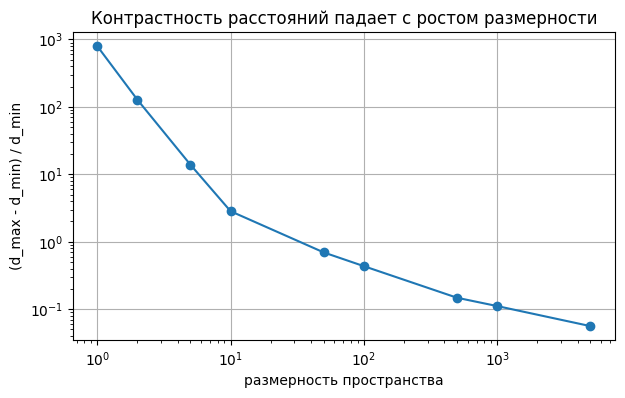

,размерность,(d_max - d_min) / d_min
0,1,796.98
1,2,127.75
2,5,13.87
3,10,2.84
4,50,0.69
5,100,0.43
6,500,0.15
7,1000,0.11
8,5000,0.06


In [19]:
rng = np.random.RandomState(0)
dims = [1, 2, 5, 10, 50, 100, 500, 1000, 5000]
contrast = []
for d in dims:
    P = rng.rand(1001, d)
    dist = np.sqrt(((P[1:] - P[0]) ** 2).sum(axis=1))
    contrast.append((dist.max() - dist.min()) / dist.min())

plt.loglog(dims, contrast, marker="o")
plt.xlabel("размерность пространства"); plt.ylabel("(d_max - d_min) / d_min")
plt.title("Контрастность расстояний падает с ростом размерности")
plt.show();
pd.DataFrame({"размерность": dims, "(d_max - d_min) / d_min": np.round(contrast, 2)})

На прямой (размерность 1) самая далекая точка в сотни раз дальше самой близкой, при размерности 100 - всего на 40% дальше, при 5000 - на 6%. «Ближайшие» и «самые далекие» становятся почти неразличимыми. (Точные значения зависят от случайных точек, но тенденция всегда одна.)

### Что делать

(1) **отбирать признаки** вручную или по важности;   
(2) **снижать размерность**, например методом главных компонент (PCA);   
(3) **масштабировать** признаки, чтобы случайные большие шкалы не доминировали. Проверим второй пункт на цифрах.

In [20]:
rows = []
for n in [5, 10, 20, 30, 64]:
    pipe = make_pipeline(PCA(n_components=n, random_state=SEED), KNeighborsClassifier(n_neighbors=3))
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv).mean()
    rows.append({"компонент PCA": n, "CV accuracy": round(s, 4)})
pd.DataFrame(rows)

,компонент PCA,CV accuracy
0,5,0.9014
1,10,0.9753
2,20,0.9841
3,30,0.9841
4,64,0.9817


**Вопрос.** Сколько компонент достаточно? Какую выгоду это дает, если у нас миллион объектов?

<details>
<summary><b>Показать ответ</b></summary>

Уже 20-30 компонент дают такое же качество, как все 64 признака, а иногда и чуть лучше (PCA убирает часть шума). Выгода: расстояние считается по меньшему числу признаков, предсказание быстрее и занимает меньше памяти. Для kNN, где вся стоимость приходится на этап предсказания, это ощутимо.

</details>

**Вывод.** kNN хорошо работает, когда признаков немного и все они осмысленны. С ростом числа бесполезных признаков качество быстро падает, потому что метод не умеет их «отключать». Перед kNN полезно отбирать признаки, снижать размерность и масштабировать данные.

## Часть 4. Оценщик квартир


Мы возьмем тот же датасет `flats.csv`, что и на семинаре 2, подготовим данные тем же способом и сравним kNN с линейной регрессией, которую вы там строили.

### Подготовка данных

* целевая переменная - **логарифм цены** (из-за скошенного распределения цены; на семинаре 2 мы это обсуждали);
* категориальные признаки (`Apartment type`, `Region`, `Renovation`) кодируем one-hot;
* станцию метро кодируем **средним значением целевой переменной на обучающей выборке**. Чтобы не допустить утечки, делаем это внутри пайплайна: кодировщик учится только на обучающих данных каждого шага кросс-валидации.

In [21]:
DATA_URL = 'https://raw.githubusercontent.com/arl20/python_2024_AI/refs/heads/main/datasets/flats.csv'

df = pd.read_csv(DATA_URL)
df['Metro station'] = df['Metro station'].str.strip()     # убираем лишние пробелы в названиях
df['Log_price'] = np.log(df['Price'])
print(df.shape)
df.head()

(22676, 13)


,Price,Apartment type,Metro station,Minutes to metro,Region,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Renovation,Log_price
0,6300000.0,Secondary,Опалиха,6.0,Moscow region,1.0,30.6,11.1,8.5,25.0,25,Cosmetic,15.656060
1,9000000.0,Secondary,Павшино,2.0,Moscow region,1.0,49.2,20.0,10.0,6.0,15,European-style renovation,16.012735
2,11090000.0,Secondary,Мякинино,14.0,Moscow region,1.0,44.7,16.2,13.1,10.0,25,Cosmetic,16.221554
3,8300000.0,Secondary,Строгино,8.0,Moscow region,1.0,35.1,16.0,11.0,12.0,33,European-style renovation,15.931766
4,6450000.0,Secondary,Опалиха,6.0,Moscow region,1.0,37.7,15.2,4.0,5.0,5,Without renovation,15.679591


In [22]:
df_enc = pd.get_dummies(df, columns=['Apartment type', 'Region', 'Renovation'], drop_first=True, dtype=int)
X_all = df_enc.drop(columns=['Price', 'Log_price'])
y_all = df_enc['Log_price']

train_x, test_x, train_y, test_y = train_test_split(X_all, y_all, test_size=0.25, random_state=42)
print("train:", train_x.shape, "| test:", test_x.shape)
train_x.head(3)

train: (17007, 13) | test: (5669, 13)


,Metro station,Minutes to metro,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Apartment type_Secondary,Region_Moscow region,Renovation_Designer,Renovation_European-style renovation,Renovation_Without renovation
13300,Красногвардейская,5.0,3.0,83.0,44.1,13.5,11.0,20,0,1,0,0,0
11436,Преображенская площадь,12.0,0.0,31.5,18.1,9.2,4.0,4,1,0,0,1,0
7228,Охотный ряд,5.0,2.0,66.0,37.0,8.0,3.0,8,1,0,0,1,0


In [23]:
class MetroMeanEncoder(BaseEstimator, TransformerMixin):
    """Заменяет станцию метро на среднюю целевую переменную по станции (считается только по обучению)."""
    def fit(self, X, y):
        t = pd.DataFrame({"station": X["Metro station"].values, "y": np.asarray(y)})
        self.mean_ = t.groupby("station")["y"].mean()
        self.fallback_ = float(np.median(y))              # для станций, которых не было в обучении
        return self

    def transform(self, X):
        X = X.copy()
        X["metro_m_enc"] = X["Metro station"].map(self.mean_).fillna(self.fallback_).values
        return X.drop(columns="Metro station")

# названия столбцов после кодировщика (понадобятся позже)
feature_names = [c for c in train_x.columns if c != "Metro station"] + ["metro_m_enc"]
print(feature_names)

['Minutes to metro', 'Number of rooms', 'Area', 'Living area', 'Kitchen area', 'Floor', 'Number of floors', 'Apartment type_Secondary', 'Region_Moscow region', 'Renovation_Designer', 'Renovation_European-style renovation', 'Renovation_Without renovation', 'metro_m_enc']


### Единая оценка моделей

Чтобы честно сравнивать, заведем единые функции оценки. Метрики: $R^2$ для логарифма цены (как на семинаре 2) и две ошибки в **рублях**: MAE (средняя абсолютная) и MedAE (медианная абсолютная).

In [24]:
preds = {}           # название модели -> предсказания на тесте
has_twin = None      # заполним в п. 4.3

def add_result(model, name):
    model.fit(train_x, train_y)
    pred = model.predict(test_x)
    preds[name] = pred
    return model, pred

def quick(name):
    """Короткая сводка по одной модели на всем тесте."""
    p = preds[name]
    return (f"{name}: R2 (лог) = {r2_score(test_y, p):.4f}, "
            f"MAE = {mean_absolute_error(np.exp(test_y), np.exp(p)) / 1e6:.2f} млн, "
            f"MedAE = {median_absolute_error(np.exp(test_y), np.exp(p)) / 1e6:.2f} млн")

def summary(names):
    """Итоговая таблица: на всем тесте и на квартирах, у которых нет двойника в обучении."""
    ok = ~has_twin
    rows = []
    for n in names:
        p = preds[n]
        rows.append({
            "модель": n,
            "R2, весь тест": r2_score(test_y, p),
            "R2, без двойников": r2_score(test_y[ok], p[ok]),
            "MAE, млн (весь тест)": mean_absolute_error(np.exp(test_y), np.exp(p)) / 1e6,
            "MAE, млн (без двойников)": mean_absolute_error(np.exp(test_y[ok]), np.exp(p[ok])) / 1e6,
            "MedAE, млн (без двойников)": median_absolute_error(np.exp(test_y[ok]), np.exp(p[ok])) / 1e6,
        })
    return pd.DataFrame(rows).set_index("модель").round(3)

# константная модель: всегда предсказываем медиану логарифма цены
class Median(BaseEstimator):
    def fit(self, X, y): self.m_ = np.median(y); return self
    def predict(self, X): return np.full(len(X), self.m_)

add_result(Median(), "константа (медиана)")
lin, pred_lin = add_result(make_pipeline(MetroMeanEncoder(), StandardScaler(), LinearRegression()), "линейная регрессия")
print(quick("линейная регрессия"))

линейная регрессия: R2 (лог) = 0.9100, MAE = 17.91 млн, MedAE = 1.56 млн


### 4.1. Первый kNN: без масштабирования и с ним

Начнем с $k=5$ и евклидовой метрики. Сначала «как есть», потом со стандартизацией признаков.

In [25]:
knn_raw, _ = add_result(make_pipeline(MetroMeanEncoder(), KNeighborsRegressor(n_neighbors=5)), "kNN k=5, без масштаба")
knn_sc, _ = add_result(make_pipeline(MetroMeanEncoder(), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
                       "kNN k=5, со стандартизацией")
print(quick("kNN k=5, без масштаба"))
print(quick("kNN k=5, со стандартизацией"))

kNN k=5, без масштаба: R2 (лог) = 0.8994, MAE = 13.21 млн, MedAE = 1.29 млн
kNN k=5, со стандартизацией: R2 (лог) = 0.9508, MAE = 10.55 млн, MedAE = 0.96 млн


Стандартизация заметно помогла. Посмотрим, **почему**: какой вклад каждый признак вносит в квадрат евклидова расстояния между двумя случайными квартирами - до и после стандартизации.

In [26]:
Z = MetroMeanEncoder().fit(train_x, train_y).transform(train_x).astype(float)
rng = np.random.RandomState(0)
pairs = rng.choice(len(Z), size=(5000, 2))

def contrib(M):
    d2 = (M[pairs[:, 0]] - M[pairs[:, 1]]) ** 2
    return d2.mean(axis=0) / d2.mean(axis=0).sum()

share = pd.DataFrame({
    "доля в расстоянии, без масштаба": contrib(Z.values),
    "доля в расстоянии, стандартизовано": contrib(((Z - Z.mean()) / Z.std()).values),
}, index=Z.columns)
(share * 100).round(1).sort_values("доля в расстоянии, без масштаба", ascending=False)

,"доля в расстоянии, без масштаба","доля в расстоянии, стандартизовано"
Area,73.5,7.7
Living area,22.6,7.8
Number of floors,1.5,7.7
Floor,0.9,7.4
Kitchen area,0.9,7.4
Minutes to metro,0.6,7.8
Number of rooms,0.0,7.7
Apartment type_Secondary,0.0,7.7
Region_Moscow region,0.0,7.9
Renovation_Designer,0.0,7.4


**Вопрос.** Какие признаки «захватывают» расстояние без масштабирования? Какие, по-вашему, несправедливо оказываются забыты? Что изменилось после стандартизации?

<details>
<summary><b>Показать ответ</b></summary>

Без масштаба около 96% расстояния определяют всего два признака: общая площадь (около 74%) и жилая площадь (около 23%), потому что у них самый большой разброс в «сырых» единицах (десятки квадратных метров). Остальные признаки практически не участвуют в выборе соседей. Среди них, например, закодированная станция метро (в логарифмических рублях она меняется в пределах нескольких десятых) и тип ремонта, хотя от района и ремонта цена зависит сильно. После стандартизации каждый признак вносит примерно одинаковую долю, около 1/13, то есть 7.7%.

Важно: стандартизация делает вклады **равными**, но не обязательно **правильными**: все признаки получают одинаковую важность, даже малополезные.

</details>

### 4.2. Подбор гиперпараметров

Переберем число соседей $k$, веса соседей (`uniform` или `distance`) и степень метрики Минковского $p$ ($p=1$ - манхэттенская, $p=2$ - евклидова). Используем кросс-валидацию на обучающей выборке и $R^2$ как метрику.

In [27]:
pipe = make_pipeline(MetroMeanEncoder(), StandardScaler(), KNeighborsRegressor())
param_grid = {
    "kneighborsregressor__n_neighbors": [1, 2, 3, 5, 7, 10, 15, 20, 30],
    "kneighborsregressor__weights": ["uniform", "distance"],
    "kneighborsregressor__p": [1, 2],
}
gs1 = GridSearchCV(pipe, param_grid, cv=KFold(5, shuffle=True, random_state=0), scoring="r2", n_jobs=-1)
gs1.fit(train_x, train_y)

print("Лучшие параметры:", {k.split("__")[1]: v for k, v in gs1.best_params_.items()})
print(f"CV R2: {gs1.best_score_:.4f}")

cvres = pd.DataFrame(gs1.cv_results_)
cvres["k"] = cvres["param_kneighborsregressor__n_neighbors"]
cvres["weights"] = cvres["param_kneighborsregressor__weights"]
cvres["p"] = cvres["param_kneighborsregressor__p"]
cvres.pivot_table(index="k", columns=["weights", "p"], values="mean_test_score").round(4)

Лучшие параметры: {'n_neighbors': 10, 'p': 1, 'weights': 'distance'}
CV R2: 0.9630


weights distance         uniform        
p              1       2       1       2
k                                       
1         0.9432  0.9373  0.9432  0.9373
2         0.9548  0.9502  0.9512  0.9465
3         0.9592  0.9540  0.9539  0.9485
5         0.9616  0.9572  0.9544  0.9496
7         0.9629  0.9581  0.9546  0.9492
10        0.9630  0.9583  0.9540  0.9483
15        0.9627  0.9577  0.9529  0.9467
20        0.9620  0.9569  0.9516  0.9453
30        0.9610  0.9556  0.9502  0.9429

In [28]:
knn_best, _ = add_result(gs1.best_estimator_, "kNN, подбор по CV")
print(quick("kNN, подбор по CV"))
print(quick("линейная регрессия"))

kNN, подбор по CV: R2 (лог) = 0.9658, MAE = 7.72 млн, MedAE = 0.66 млн
линейная регрессия: R2 (лог) = 0.9100, MAE = 17.91 млн, MedAE = 1.56 млн


kNN с подобранными гиперпараметрами **заметно** лучше линейной модели по всем трем метрикам: $R^2$ около 0.97 против 0.91, ошибка в рублях более чем вдвое меньше.

**Вопрос.** Радоваться или насторожиться? Мы всего лишь взяли самый простой алгоритм, который «ничего не учит». Что должно вызвать подозрения?

<details>
<summary><b>Показать ответ</b></summary>

Подозрительно, что очень простой метод обгоняет линейную модель с хорошо подготовленными признаками. В таких случаях полезно спросить себя, не «подсматривает» ли модель. Для kNN есть классическая причина: если в данных есть **почти одинаковые объекты**, то при разбиении они могут оказаться и в обучении, и в тесте. Тогда для тестового объекта в обучении найдется «близнец» с почти такой же ценой, и kNN просто запомнит ответ. Проверим, есть ли такие объекты.

</details>

### 4.3. Расследование: дубликаты в данных

Для каждой квартиры составим «ключ» из всех признаков (кроме цены) и посмотрим, сколько квартир имеют полностью совпадающих двойников.

In [29]:
feat_cols = [c for c in df.columns if c not in ("Price", "Log_price")]
df["twin_key"] = df[feat_cols].astype(str).agg("|".join, axis=1)

counts = df["twin_key"].map(df["twin_key"].value_counts())
print(f"Строк в датасете: {len(df)}")
print(f"Строк, у которых есть хотя бы один двойник по признакам: {(counts > 1).sum()} ({(counts > 1).mean():.1%})")

# пример группы двойников
key = df.loc[counts.idxmax(), "twin_key"]
df.loc[df["twin_key"] == key, ["Price", "Metro station", "Area", "Floor", "Number of floors", "Renovation"]].head(6)

Строк в датасете: 22676
Строк, у которых есть хотя бы один двойник по признакам: 6457 (28.5%)


,Price,Metro station,Area,Floor,Number of floors,Renovation
1387,730000000.0,Спортивная,517.86,14.0,15,Without renovation
1388,747200000.0,Спортивная,517.86,14.0,15,Without renovation
1389,747270000.0,Спортивная,517.86,14.0,15,Without renovation
1390,747000000.0,Спортивная,517.86,14.0,15,Without renovation
2802,730000000.0,Спортивная,517.86,14.0,15,Without renovation
2803,747200000.0,Спортивная,517.86,14.0,15,Without renovation


Одна и та же квартира (те же площадь, этаж, станция метро) встречается несколько раз, причем цены у копий могут слегка различаться. Для kNN это опасно: посмотрим, как это влияет на тест. У скольких тестовых квартир есть точный двойник **в обучающей выборке**?

In [30]:
train_keys = set(df.loc[train_x.index, "twin_key"])
has_twin = df.loc[test_x.index, "twin_key"].isin(train_keys).values
print(f"У {has_twin.mean():.1%} тестовых квартир есть двойник в обучении")

p_knn = knn_best.predict(test_x)
p_lin = lin.predict(test_x)
print()
print(f"R2 (лог) kNN:      с двойниками {r2_score(test_y[has_twin], p_knn[has_twin]):.4f} | без двойников {r2_score(test_y[~has_twin], p_knn[~has_twin]):.4f}")
print(f"R2 (лог) линейная: с двойниками {r2_score(test_y[has_twin], p_lin[has_twin]):.4f} | без двойников {r2_score(test_y[~has_twin], p_lin[~has_twin]):.4f}")

У 23.6% тестовых квартир есть двойник в обучении

R2 (лог) kNN:      с двойниками 0.9981 | без двойников 0.9533
R2 (лог) линейная: с двойниками 0.9254 | без двойников 0.9027


**Вопрос.** Что мы выяснили? Откуда в данных двойники, и это «ошибка» или нормально?

<details>
<summary><b>Показать ответ</b></summary>

Почти четверть тестовых квартир имеет в обучении точного двойника, и на них kNN предсказывает практически идеально ($R^2 \approx 0.998$): он просто находит ту же квартиру и возвращает ее цену. На квартирах без двойников $R^2$ ниже (около 0.953), так что общая оценка 0.966 **завышена**. Но вывод «kNN лучше линейной модели» остается в силе: без двойников у линейной модели около 0.903.

Откуда двойники: одно и то же объявление, выложенное несколько раз (разными агентствами или в разные дни), и типовые квартиры в новостройках одного дома (одинаковые планировка, площадь, этаж, станция). Это не ошибка данных, и в реальной системе такое тоже встречается: если квартиру уже продавали, ее цена - лучшая подсказка. Но чтобы понять, **как хорошо модель оценивает новую, ранее не виденную квартиру**, двойников нужно разнести: если квартира в тесте, то ее двойников не должно быть в обучении.

</details>

### 4.4. Честная оценка: смотрим на квартиры без двойников

Подбор гиперпараметров мы делали обычной кросс-валидацией. Двойников можно было бы разнести по блокам кросс-валидации, но на выбор параметров здесь это не влияет. Важнее другое: **итоговое качество** нужно смотреть отдельно на тестовых квартирах, у которых нет двойника в обучении. Это честная оценка способности модели оценивать **новую** квартиру.

In [31]:
pred_best = preds["kNN, подбор по CV"]
summary(["константа (медиана)", "линейная регрессия", "kNN k=5, без масштаба", "kNN k=5, со стандартизацией",
         "kNN, подбор по CV"])

,"R2, весь тест","R2, без двойников","MAE, млн (весь тест)","MAE, млн (без двойников)","MedAE, млн (без двойников)"
модель,,,,,
константа (медиана),-0.075,-0.121,28.840,28.672,5.676
линейная регрессия,0.910,0.903,17.906,15.199,1.933
"kNN k=5, без масштаба",0.899,0.874,13.211,14.220,1.952
"kNN k=5, со стандартизацией",0.951,0.941,10.552,10.977,1.289
"kNN, подбор по CV",0.966,0.953,7.717,9.995,1.116


В таблице две группы колонок: на всем тесте и только на квартирах без двойника в обучении. Вывод «kNN лучше линейной модели» остается в силе и на честной оценке, но разрыв меньше, чем казалось: у kNN $R^2$ около 0.95 вместо 0.97, а у линейной модели около 0.90.

### 4.5. «Аналоги» для конкретной квартиры

Главное преимущество kNN перед линейной моделью - прозрачность: прогноз цены целиком объясняется конкретными квартирами. Возьмем один типичный случай (тестовая московская квартира без двойников в обучении, прогноз которой ошибается меньше чем на 8%; неудачный случай разберем в п. 4.6) и покажем ее вместе со всеми аналогами, которые использует модель (их столько, сколько указано в $k$).

In [32]:
show_cols = ["Price", "Metro station", "Region", "Apartment type", "Renovation",
             "Number of rooms", "Area", "Kitchen area", "Floor", "Number of floors", "Minutes to metro"]

def show_analogs(model, x_row, true_price=None):
    """Печатает прогноз и таблицу ближайших аналогов для строки x_row (формат train_x)."""
    z = model[:-1].transform(x_row)                      # кодирование + масштаб, как внутри пайплайна
    knn = model[-1]
    dist, ind = knn.kneighbors(z)                        # столько соседей, сколько задано в модели
    analogs = df.loc[train_x.index[ind[0]], show_cols].copy()
    w = 1 / dist[0] if knn.weights == "distance" else np.ones(len(dist[0]))
    analogs.insert(0, "вес", (w / w.sum()).round(2))
    analogs.insert(0, "расстояние", dist[0].round(2))
    analogs["Price"] = (analogs["Price"] / 1e6).round(2)
    analogs = analogs.rename(columns={"Price": "цена, млн"})
    pred_price = np.exp(model.predict(x_row)[0]) / 1e6
    print(f"Прогноз: {pred_price:.2f} млн руб." + (f" | реальная цена: {true_price / 1e6:.2f} млн руб." if true_price else ""))
    print("(прогноз - взвешенное среднее логарифмов цен соседей, возвращенное к рублям)")
    return analogs

# берем типичный случай: московская квартира без двойников, цена 12-20 млн, прогноз ошибается меньше чем на 8%
price_te = np.exp(test_y.values)
ok = ~has_twin & (test_x["Region_Moscow region"].values == 0) & (price_te > 12e6) & (price_te < 20e6) & (np.abs(np.exp(pred_best) / price_te - 1) < 0.08)
i = np.where(ok)[0][0]
idx = test_x.index[i]
print("Оцениваемая квартира:")
display(df.loc[[idx], show_cols].rename(columns={"Price": "цена"}))
show_analogs(knn_best, test_x.iloc[[i]], true_price=df.loc[idx, "Price"])

Оцениваемая квартира:


,цена,Metro station,Region,Apartment type,Renovation,Number of rooms,Area,Kitchen area,Floor,Number of floors,Minutes to metro
18451,12768000.0,Аннино,Moscow,New building,Cosmetic,2.0,79.8,10.3,5.0,22,7.0


Прогноз: 13.09 млн руб. | реальная цена: 12.77 млн руб.
(прогноз - взвешенное среднее логарифмов цен соседей, возвращенное к рублям)


,расстояние,вес,"цена, млн",Metro station,Region,Apartment type,Renovation,Number of rooms,Area,Kitchen area,Floor,Number of floors,Minutes to metro
16475,0.06,0.29,13.24,Аннино,Moscow,New building,Cosmetic,2.0,79.5,9.9,5.0,22,7.0
15093,0.06,0.29,12.57,Аннино,Moscow,New building,Cosmetic,2.0,79.5,9.9,5.0,22,7.0
15092,0.18,0.11,12.57,Аннино,Moscow,New building,Cosmetic,2.0,79.7,10.0,4.0,22,7.0
18449,0.27,0.07,13.64,Аннино,Moscow,New building,Cosmetic,2.0,80.0,10.3,3.0,22,7.0
18454,0.30,0.06,14.61,Аннино,Moscow,New building,Cosmetic,2.0,85.2,11.5,5.0,22,7.0
22644,0.47,0.04,13.74,Аннино,Moscow,New building,Cosmetic,2.0,75.7,12.9,5.0,22,7.0
22640,0.54,0.03,14.46,Аннино,Moscow,New building,Cosmetic,2.0,79.9,13.3,4.0,22,7.0
18460,0.55,0.03,12.10,Аннино,Moscow,New building,Cosmetic,2.0,75.6,10.4,4.0,22,7.0
16477,0.57,0.03,12.51,Аннино,Moscow,New building,Cosmetic,2.0,75.6,11.4,3.0,22,7.0
16478,0.67,0.03,14.02,Аннино,Moscow,New building,Cosmetic,2.0,85.0,11.4,2.0,22,7.0


**Вопрос.** Насколько вы доверяете такому прогнозу? По каким признакам аналоги похожи на оцениваемую квартиру, а по каким отличаются? Разумно ли использовать здесь расстояние именно по всем признакам?

<details>
<summary><b>Показать ответ</b></summary>

В этом примере все аналоги - квартиры из того же дома (новостройка в Аннино, 22 этажа) с похожей площадью, расстояния до них очень малы, цены лежат в узком диапазоне 12-15 млн, и прогноз (13.1 млн) близок к реальной цене (12.8 млн). Для типовых новостроек kNN особенно силен: аналогов много. Для вторичного жилья они встречаются реже.

В целом прогноз выглядит убедительно, когда у аналогов близкие площадь, ремонт и этажность, а цены собраны в узком диапазоне. Если аналоги сильно различаются по цене, прогноз ненадежен, и разброс цен соседей сам по себе - полезная мера неуверенности.

Обратите внимание: аналоги могут быть с **других станций метро**. Станцию мы закодировали средним уровнем цен, поэтому «близкими» оказываются станции с похожим ценовым уровнем, а не обязательно соседние по карте. Это следствие выбранного кодирования. Расстояние по всем признакам - вообще упрощение: оценщик скорее придал бы больший вес району и площади, чем этажу.

</details>

**Задание** Оцените «свою» квартиру: измените параметры в вызове `new_flat` и посмотрите на прогноз и аналоги. Попробуйте менять станцию метро, площадь, ремонт. Как меняется прогноз и состав аналогов? Какая квартира получила самое «несогласное» множество соседей?

In [45]:
msk = df[df["Region"] == "Moscow"]["Metro station"].value_counts()
print("Самые частые станции в Москве:", list(msk.index[:8]))     # можно взять любую станцию из датасета

def new_flat(station, minutes, rooms, area, living, kitchen, floor, floors,
             region="Moscow", kind="Secondary", renovation="Cosmetic"):
    # kind: "Secondary" или "New building"; region: "Moscow" или "Moscow region"
    # renovation: "Cosmetic", "European-style renovation", "Without renovation", "Designer"
    row = {c: 0 for c in train_x.columns}
    row.update({"Metro station": station, "Minutes to metro": minutes, "Number of rooms": rooms, "Area": area,
                "Living area": living, "Kitchen area": kitchen, "Floor": floor, "Number of floors": floors})
    row["Apartment type_Secondary"] = int(kind == "Secondary")
    row["Region_Moscow region"] = int(region != "Moscow")
    for rn in ["Designer", "European-style renovation", "Without renovation"]:
        row[f"Renovation_{rn}"] = int(renovation == rn)
    return pd.DataFrame([row])

my_flat = new_flat(station="Братиславская", minutes=10, rooms=2, area=55, living=32, kitchen=9, floor=7, floors=16)
show_analogs(knn_best, my_flat)

Самые частые станции в Москве: ['Депо', 'Братиславская', 'Каширская', 'ЗИЛ', 'Минская', 'Варшавская', 'Аминьевская', 'Народное Ополчение']
Прогноз: 14.86 млн руб.
(прогноз - взвешенное среднее логарифмов цен соседей, возвращенное к рублям)


,расстояние,вес,"цена, млн",Metro station,Region,Apartment type,Renovation,Number of rooms,Area,Kitchen area,Floor,Number of floors,Minutes to metro
7370,0.69,0.12,15.50,Братиславская,Moscow,Secondary,Cosmetic,2.0,51.0,8.5,5.0,17,11.0
6767,0.74,0.11,17.00,Селигерская,Moscow,Secondary,Cosmetic,2.0,52.0,9.8,7.0,13,10.0
6785,0.75,0.11,17.29,Калитники,Moscow,Secondary,Cosmetic,2.0,59.0,10.0,7.0,14,12.0
6912,0.78,0.11,14.60,Митино,Moscow,Secondary,Cosmetic,2.0,53.6,9.1,5.0,14,10.0
7702,0.80,0.11,13.25,Некрасовка,Moscow,Secondary,Cosmetic,2.0,54.4,9.2,10.0,17,9.0
6611,0.92,0.09,15.20,Новокосино,Moscow,Secondary,Cosmetic,2.0,51.7,8.4,9.0,17,10.0
7123,0.95,0.09,13.50,Улица Старокачаловская,Moscow,Secondary,Cosmetic,2.0,54.0,11.1,8.0,17,8.0
6994,0.98,0.09,13.50,Новокосино,Moscow,Secondary,Cosmetic,2.0,54.5,9.0,6.0,17,12.0
6632,0.98,0.09,12.50,Бунинская Аллея,Moscow,Secondary,Cosmetic,2.0,54.0,11.1,4.0,16,9.0
6475,1.02,0.08,16.00,Калитники,Moscow,Secondary,Cosmetic,2.0,56.4,10.0,5.0,14,12.0


### 4.6. Где kNN ошибается, и как об этом узнать заранее

Посмотрим на прогнозы обеих моделей на тестовых квартирах без двойников и на то, как ошибка зависит от цены квартиры.

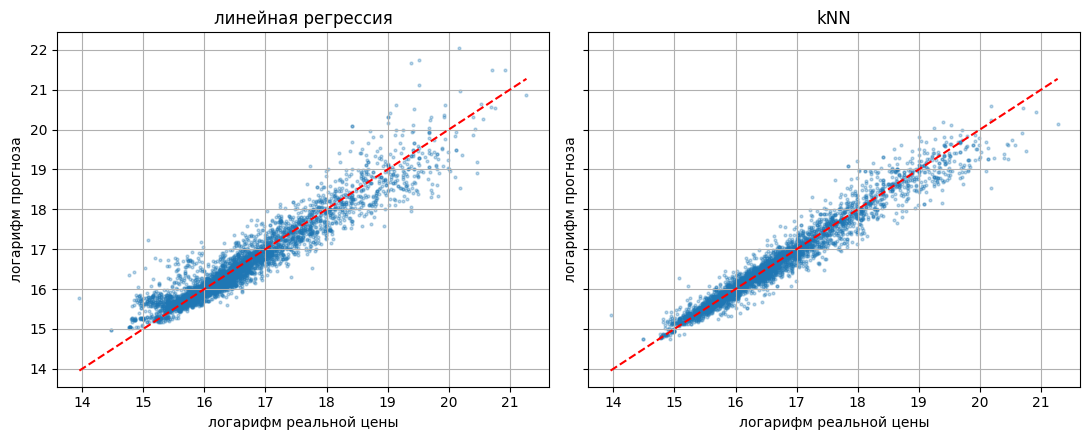

,"kNN: медианная ошибка, %","линейная: медианная ошибка, %"
"квинтиль цены, млн",,
"(1.149, 6.873]",6.7,15.5
"(6.873, 10.7]",7.4,9.5
"(10.7, 16.143]",7.1,12.7
"(16.143, 35.999]",11.9,15.8
"(35.999, 1732.171]",20.5,28.0


In [34]:
mask = ~has_twin
y_true = test_y.values[mask]
p_k = knn_best.predict(test_x)[mask]
p_l = lin.predict(test_x)[mask]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, p, t in zip(axes, [p_l, p_k], ["линейная регрессия", "kNN"]):
    ax.scatter(y_true, p, s=4, alpha=0.3)
    lim = [y_true.min(), y_true.max()]
    ax.plot(lim, lim, "r--")
    ax.set_title(t); ax.set_xlabel("логарифм реальной цены"); ax.set_ylabel("логарифм прогноза")
plt.tight_layout(); plt.show();

q = pd.qcut(np.exp(y_true) / 1e6, 5)
err = pd.DataFrame({
    "квинтиль цены, млн": q,
    "kNN: медианная ошибка, %": np.abs(np.exp(p_k) / np.exp(y_true) - 1) * 100,
    "линейная: медианная ошибка, %": np.abs(np.exp(p_l) / np.exp(y_true) - 1) * 100,
}).groupby("квинтиль цены, млн").median().round(1)
err

**Вопрос.** Где обе модели ошибаются сильнее всего? Почему kNN не может предсказать цену выше максимальной в обучающей выборке?

<details>
<summary><b>Показать ответ</b></summary>

Сильнее всего - на самых дорогих квартирах: их мало, они уникальны, у них нет близких аналогов. kNN предсказывает среднее ответов соседей, поэтому его прогноз всегда лежит в диапазоне цен, виденных в обучении, и он **не умеет экстраполировать** за этот диапазон; линейная модель экстраполирует (иногда обоснованно, иногда нет).

</details>

Теперь посмотрим на **самую грубую ошибку** среди московских тестовых квартир без двойников и на ее аналоги.

In [35]:
cand = np.where(~has_twin & (test_x["Region_Moscow region"].values == 0))[0]
j = cand[np.argmax(np.abs(knn_best.predict(test_x.iloc[cand]) - test_y.values[cand]))]
idx = test_x.index[j]
display(df.loc[[idx], show_cols].rename(columns={"Price": "цена"}))
show_analogs(knn_best, test_x.iloc[[j]], true_price=df.loc[idx, "Price"])

,цена,Metro station,Region,Apartment type,Renovation,Number of rooms,Area,Kitchen area,Floor,Number of floors,Minutes to metro
10709,583719000.0,Минская,Moscow,Secondary,Designer,5.0,160.0,16.0,2.0,9,25.0


Прогноз: 111.00 млн руб. | реальная цена: 583.72 млн руб.
(прогноз - взвешенное среднее логарифмов цен соседей, возвращенное к рублям)


,расстояние,вес,"цена, млн",Metro station,Region,Apartment type,Renovation,Number of rooms,Area,Kitchen area,Floor,Number of floors,Minutes to metro
10673,3.31,0.12,130.00,Щукинская,Moscow,Secondary,Designer,4.0,195.0,17.0,2.0,6,33.0
3966,3.88,0.10,92.00,Минская,Moscow,Secondary,Designer,5.0,139.0,18.1,3.0,13,28.0
11087,3.92,0.10,225.00,Тверская,Moscow,Secondary,Designer,5.0,173.0,15.0,4.0,12,12.0
9752,3.99,0.10,74.74,ЗИЛ,Moscow,Secondary,Designer,5.0,138.4,18.1,3.0,15,22.0
10488,4.03,0.10,156.70,Курская,Moscow,Secondary,Designer,5.0,159.0,25.0,2.0,11,11.0
559,4.05,0.10,85.00,Чистые пруды,Moscow,Secondary,Designer,4.0,161.0,15.0,2.0,6,11.0
10900,4.07,0.10,150.00,Парк Победы,Moscow,Secondary,Designer,4.0,137.7,17.0,1.0,10,10.0
9753,4.12,0.10,75.42,ЗИЛ,Moscow,Secondary,Designer,5.0,138.4,18.1,4.0,15,22.0
10692,4.29,0.09,104.90,Кутузовская,Moscow,Secondary,Designer,5.0,189.0,15.0,6.0,9,8.0
10401,4.34,0.09,83.00,Улица 1905 года,Moscow,Secondary,Designer,5.0,169.0,20.0,6.0,10,11.0


**Вопрос.** Что пошло не так? Это ошибка модели или данных?

<details>
<summary><b>Показать ответ</b></summary>

Квартира 160 м² с дизайнерским ремонтом на станции Минская продана за 584 млн руб., а ее ближайшие аналоги стоят от 75 до 225 млн: прогноз 111 млн, ошибка в 5 раз. Сигналы тревоги видны в самой таблице: расстояния до аналогов 3.3-4.3 (у типичной квартиры из предыдущего примера они меньше 1), а цены аналогов сильно различаются между собой. Квартира либо реально уникальна, либо в объявлении ошибка. kNN может дать только среднее по аналогам, и если цена объекта на порядок выше цен соседей, он не угадает: на ошибках такого рода и видно, что метод **не умеет экстраполировать** за диапазон виденных значений. Полезный вывод: большое расстояние до аналогов и большой разброс их цен - готовый признак того, что прогнозу доверять нельзя (проверим на всем тесте ниже).

</details>

Раз ошибка растет там, где мало аналогов, можно **заранее** оценивать надежность прогноза: по расстоянию до ближайших соседей. Проверим: сгруппируем тестовые квартиры по среднему расстоянию до 10 соседей и посмотрим, как растет ошибка.

In [36]:
knn_model = knn_best[-1]
Zt = knn_best[:-1].transform(test_x)
dist, _ = knn_model.kneighbors(Zt, n_neighbors=10)
mean_dist = dist.mean(axis=1)[mask]

abs_err = np.abs(p_k - y_true)
tab = pd.DataFrame({"среднее расстояние до 10 соседей": pd.qcut(mean_dist, 4, labels=["1 (близкие)", "2", "3", "4 (далекие)"]),
                    "медианная |ошибка| (лог)": abs_err}).groupby("среднее расстояние до 10 соседей").median().round(3)
print("Корреляция Спирмена (расстояние, |ошибка|):", round(pd.Series(mean_dist).corr(pd.Series(abs_err), method="spearman"), 3))
tab

Корреляция Спирмена (расстояние, |ошибка|): 0.46


,медианная |ошибка| (лог)
среднее расстояние до 10 соседей,
1 (близкие),0.043
2,0.083
3,0.126
4 (далекие),0.186


Объекты, у которых ближайшие аналоги далеко, ошибаются чаще. Это практичный сигнал: если аналогов мало или они далеко, пользователю стоит показать предупреждение «оценка приблизительная».

**Вывод.** kNN-регрессия на квартирах работает как метод сравнимых продаж и легко объясняется показом аналогов. Три главных практических урока: (1) без масштабирования признаков расстояние определяют признаки с самой большой шкалой, и kNN теряет качество; (2) метод запоминает данные, поэтому дубликаты между обучением и тестом дают завышенную оценку: качество нужно смотреть отдельно на объектах без двойников; (3) расстояние до соседей - готовый индикатор надежности прогноза, а за пределами диапазона обучающих цен kNN не умеет предсказывать.

## Часть 5. kNN против остальных

Посмотрим, как kNN выглядит на фоне других классификаторов, которые мы проходим на этом курсе: SVM (линейный и с ядром RBF), решающее дерево, случайный лес и наивный байес. Три синтетических набора данных: две «луны», два вложенных кольца и почти линейно разделимые классы. Добавим kNN с $k=3$ и $k=15$, чтобы еще раз увидеть влияние $k$.

Круги на картинках - обучающие объекты, квадраты - тестовые (полупрозрачные). В правом нижнем углу - accuracy на тесте.

In [37]:
names = ["kNN (k=3)", "kNN (k=15)", "Linear SVM", "RBF SVM", "Decision Tree", "Random Forest", "Naive Bayes"]

def make_classifiers():
    return [
        KNeighborsClassifier(3),
        KNeighborsClassifier(15),
        SVC(kernel="linear", C=0.025, random_state=SEED),
        SVC(gamma=2, C=1, random_state=SEED),
        DecisionTreeClassifier(max_depth=5, random_state=SEED),
        RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1, random_state=SEED),
        GaussianNB(),
    ]

X_lin, y_lin = make_classification(n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1)
X_lin += 2 * np.random.RandomState(2).uniform(size=X_lin.shape)

datasets = {
    "Луны": make_moons(noise=0.3, random_state=0),
    "Кольца": make_circles(noise=0.2, factor=0.5, random_state=1),
    "Почти линейные": (X_lin, y_lin),
}

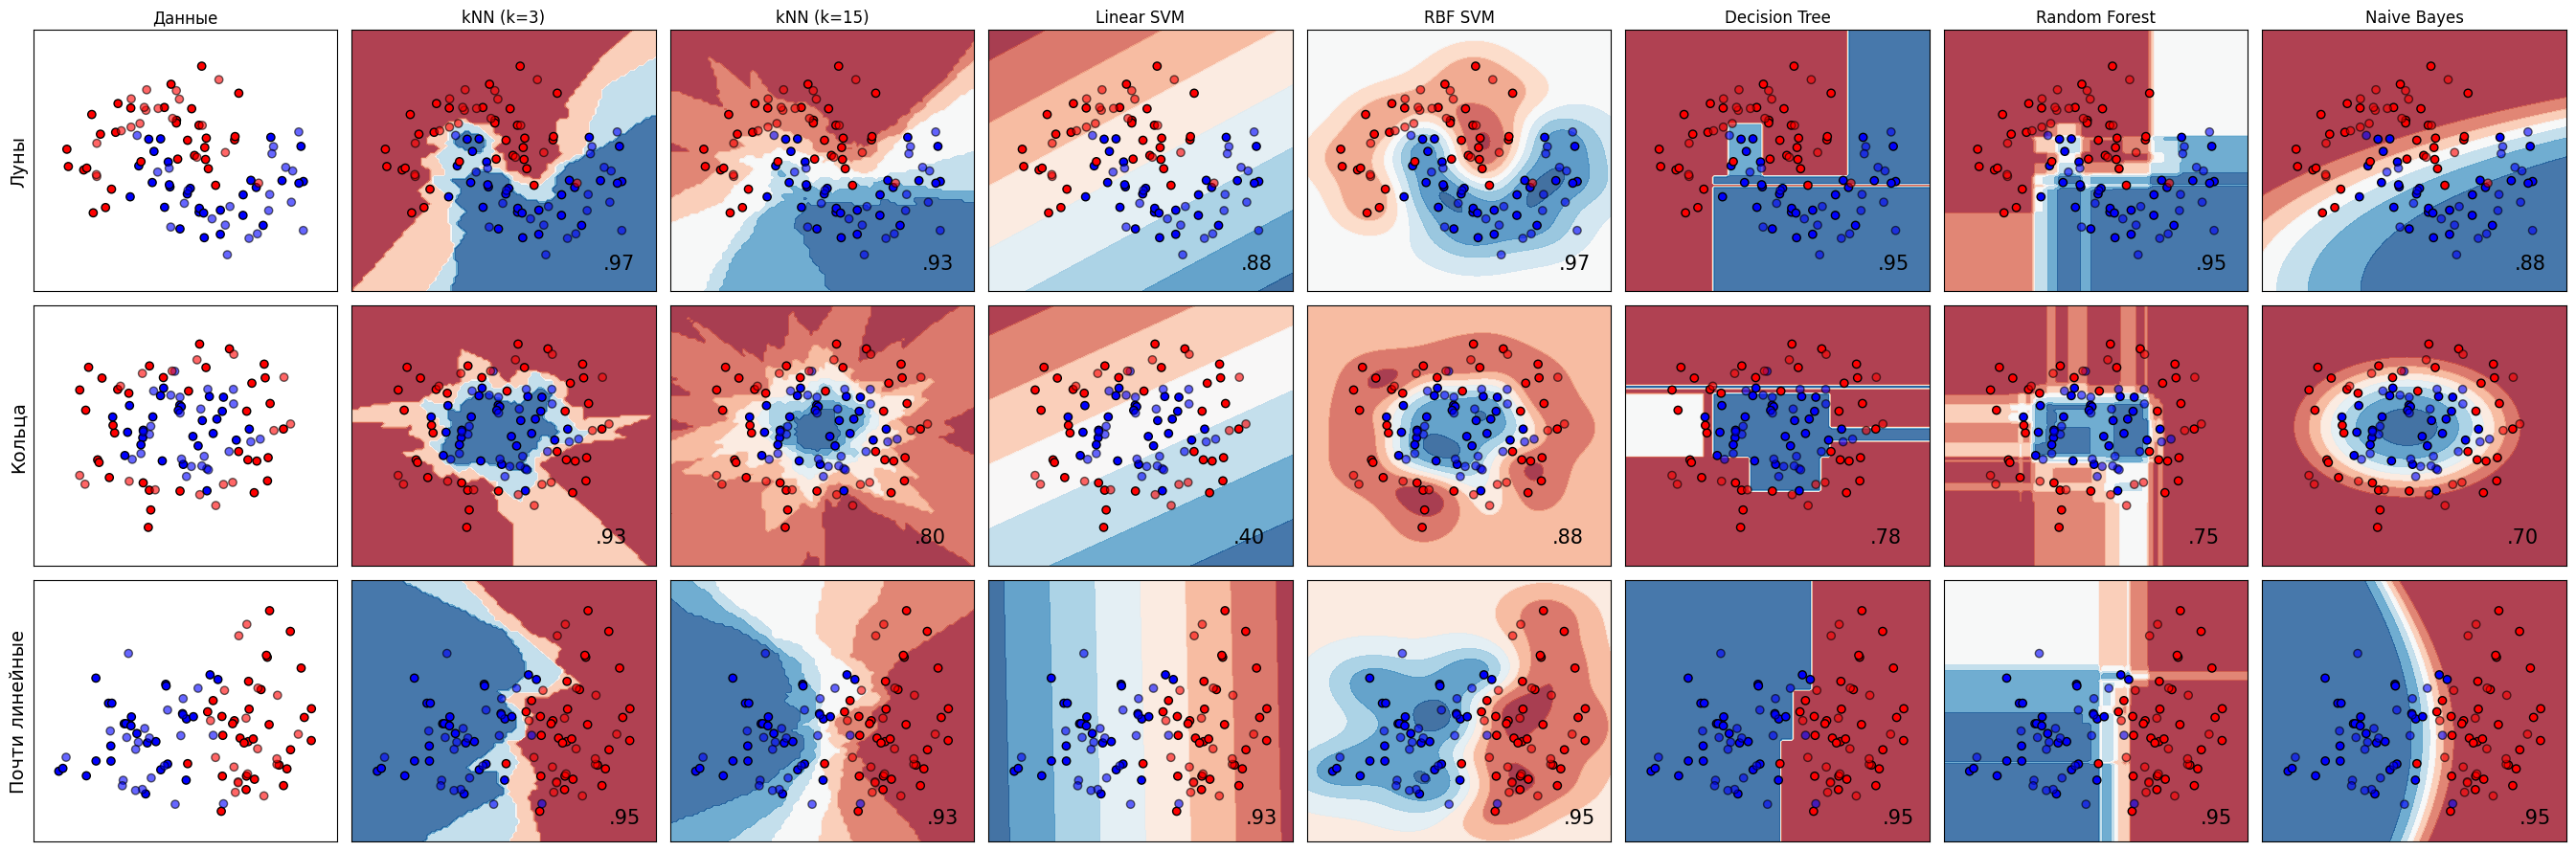

In [38]:
cm = plt.cm.RdBu
cm_bright = ListedColormap(["#FF0000", "#0000FF"])

fig = plt.figure(figsize=(27, 9))
i = 1
for ds_name, (X_d, y_d) in datasets.items():
    Xa, Xb, ya, yb = train_test_split(X_d, y_d, test_size=0.4, random_state=SEED)
    x_min, x_max = X_d[:, 0].min() - 0.5, X_d[:, 0].max() + 0.5
    y_min, y_max = X_d[:, 1].min() - 0.5, X_d[:, 1].max() + 0.5

    ax = plt.subplot(len(datasets), len(names) + 1, i)
    ax.scatter(Xa[:, 0], Xa[:, 1], c=ya, cmap=cm_bright, edgecolors="k")
    ax.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap=cm_bright, alpha=0.6, edgecolors="k")
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max); ax.set_xticks(()); ax.set_yticks(())
    ax.set_ylabel(ds_name, fontsize=14)
    if i == 1:
        ax.set_title("Данные")
    i += 1

    for name, clf in zip(names, make_classifiers()):
        ax = plt.subplot(len(datasets), len(names) + 1, i)
        clf = make_pipeline(StandardScaler(), clf).fit(Xa, ya)
        score = clf.score(Xb, yb)
        DecisionBoundaryDisplay.from_estimator(clf, X_d, cmap=cm, alpha=0.8, ax=ax, eps=0.5)
        ax.scatter(Xa[:, 0], Xa[:, 1], c=ya, cmap=cm_bright, edgecolors="k")
        ax.scatter(Xb[:, 0], Xb[:, 1], c=yb, cmap=cm_bright, edgecolors="k", alpha=0.6)
        ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max); ax.set_xticks(()); ax.set_yticks(())
        if i <= len(names) + 1:
            ax.set_title(name)
        ax.text(x_max - 0.3, y_min + 0.3, ("%.2f" % score).lstrip("0"), size=15, horizontalalignment="right")
        ax.grid(False)
        i += 1
plt.tight_layout()
plt.show();

По одной картинке выводы делать опасно: в каждом наборе всего 100 точек, в тесте 40, и одна лишняя ошибка меняет точность на 0.025. Повторим эксперимент на 30 случайных разбиениях и посмотрим на среднее и разброс.

In [39]:
rows = {n: {} for n in names}
for ds_name, (X_d, y_d) in datasets.items():
    accs = {n: [] for n in names}
    for seed in range(30):
        Xa, Xb, ya, yb = train_test_split(X_d, y_d, test_size=0.4, random_state=seed)
        for name, clf in zip(names, make_classifiers()):
            accs[name].append(make_pipeline(StandardScaler(), clf).fit(Xa, ya).score(Xb, yb))
    for n in names:
        rows[n][ds_name] = f"{np.mean(accs[n]):.3f} ± {np.std(accs[n]):.3f}"
pd.DataFrame(rows).T

,Луны,Кольца,Почти линейные
kNN (k=3),0.937 ± 0.035,0.807 ± 0.056,0.940 ± 0.031
kNN (k=15),0.863 ± 0.056,0.672 ± 0.115,0.915 ± 0.036
Linear SVM,0.830 ± 0.043,0.457 ± 0.037,0.923 ± 0.033
RBF SVM,0.924 ± 0.036,0.857 ± 0.046,0.928 ± 0.029
Decision Tree,0.873 ± 0.058,0.788 ± 0.058,0.902 ± 0.039
Random Forest,0.898 ± 0.040,0.812 ± 0.055,0.908 ± 0.032
Naive Bayes,0.838 ± 0.039,0.841 ± 0.059,0.936 ± 0.027


**Вопросы.** (1) Какой классификатор лучше на каждом наборе? Какие различия значимы, а какие нет (сравните с разбросом)? (2) Почему линейный SVM и наивный Байес плохо справляются с кольцами? (3) Почему kNN с $k=15$ хуже, чем с $k=3$, хотя в части 1 большее $k$ помогало?

<details>
<summary><b>Показать ответ</b></summary>

(1) На лунах лучшие kNN с $k=3$ (0.94) и RBF SVM (0.92), на кольцах RBF SVM (0.86) и наивный Байес (0.84); линейный SVM на кольцах проваливается (0.46, хуже монетки), на почти линейных данных все методы в диапазоне 0.90-0.94. Различия между лучшими методами на каждом наборе в пределах одного-двух стандартных отклонений, то есть они неразличимы. Значимыми считаем различия, заметно превышающие стандартное отклонение (например, линейный SVM против остальных на лунах и кольцах).

(2) Линейный SVM проводит прямую, а один класс окружает другой: никакая прямая их не разделит. Наивный Байес справляется неожиданно неплохо: центры колец совпадают, но дисперсии у классов разные (у внутреннего кольца разброс меньше), а гауссовский байес оценивает дисперсию отдельно для каждого класса, поэтому получает эллиптическую границу (как на картинке в лекции). На других данных такой трюк не сработает.

(3) При $k=3$ граница рваная, при $k=15$ гладкая. Здесь $k=15$ даже хуже $k=3$: обучающая выборка всего 60 объектов, и 15 соседей - это четверть выборки, граница сглаживается слишком сильно. Оптимальное $k$ зависит от размера выборки (в части 1 на 210 обучающих объектах оптимум был около 19).

</details>

### Мостик к Kernel SVM

RBF SVM из этой таблицы - ближайший «родственник» kNN. Ядро $K(a, b) = \exp(-\gamma\|a-b\|^2)$ - тоже мера сходства: чем ближе объекты, тем ближе значение ядра к 1. Предсказание SVM - взвешенная сумма ядер по **опорным** объектам, то есть тоже своего рода «взвешенное голосование похожих». Отличие в том, что kNN хранит все объекты и считает все веса на лету, а SVM **учится** выбирать небольшое число опорных объектов и подбирать их веса. Об этом - в следующей части лекции.

**Вывод.** Нет метода, который всегда лучший: линейные модели выигрывают на линейных данных, нелинейные - на нелинейных. kNN не требует обучения, интерпретируем и неплохо ловит сложные границы, но платит за это памятью, скоростью предсказания и чувствительностью к масштабу и шуму. Сравнивать методы по одной картинке и одному разбиению нельзя: нужно усреднять по разбиениям.

## Часть 6 (бонус по желанию). Другие применения kNN

### 6.1. Заполнение пропусков: `KNNImputer`

В лекции 2 при обсуждении пропусков упоминалось «заполнение моделью (kNN)». Проверим, стоит ли оно усилий. Возьмем числовые признаки квартир, искусственно «потеряем» 15% значений площади кухни и сравним три способа восстановить их: средним, медианой и `KNNImputer`, который берет среднее значение признака у ближайших соседей.

In [40]:
num_cols = ["Minutes to metro", "Number of rooms", "Area", "Living area", "Kitchen area", "Floor", "Number of floors"]
A = df[num_cols].values.astype(float)
col = num_cols.index("Kitchen area")

rng = np.random.RandomState(SEED)
lost = rng.rand(len(A)) < 0.15
A_miss = A.copy()
A_miss[lost, col] = np.nan
truth = A[lost, col]

def evaluate_fill(filled, name):
    est = filled[lost, col]
    return {"способ": name, "MAE, кв. м": np.mean(np.abs(est - truth)), "RMSE, кв. м": np.sqrt(np.mean((est - truth) ** 2))}

rows = [
    evaluate_fill(np.where(np.isnan(A_miss), np.nanmean(A_miss, axis=0), A_miss), "среднее"),
    evaluate_fill(np.where(np.isnan(A_miss), np.nanmedian(A_miss, axis=0), A_miss), "медиана"),
]
sc = StandardScaler().fit(A_miss)                     # StandardScaler игнорирует пропуски
for k in [5, 15]:
    filled = sc.inverse_transform(KNNImputer(n_neighbors=k).fit_transform(sc.transform(A_miss)))
    rows.append(evaluate_fill(filled, f"KNNImputer (k={k})"))
pd.DataFrame(rows).round(2)

,способ,"MAE, кв. м","RMSE, кв. м"
0,среднее,4.98,7.55
1,медиана,4.72,7.83
2,KNNImputer (k=5),2.56,4.67
3,KNNImputer (k=15),2.67,4.63


**Вопрос.** Почему kNN восстанавливает кухню лучше среднего и медианы? Зачем перед `KNNImputer` стандартизовали признаки?

<details>
<summary><b>Показать ответ</b></summary>

Среднее и медиана не учитывают, что кухня в 100-метровой квартире и в 25-метровой студии - разные вещи. kNN находит квартиры, **похожие по остальным признакам** (площадь, число комнат), и берет значение у них. Стандартизация нужна по той же причине, что и везде: иначе расстояние определяют признаки с большой шкалой.

</details>

### 6.2. Поиск аномалий

Если у объекта все ближайшие соседи далеко, то он необычен. Среднее расстояние до $k$ ближайших соседей - простая и работающая оценка «аномальности». Найдем самые необычные квартиры в датасете: те самые «подозрительные» объекты, которые мы замечали на семинарах 1-2.

In [41]:
cols_an = ["Log_price", "Area", "Living area", "Kitchen area", "Number of rooms", "Minutes to metro", "Floor", "Number of floors"]
Za = StandardScaler().fit_transform(df[cols_an])
nn = NearestNeighbors(n_neighbors=6).fit(Za)
dist, _ = nn.kneighbors(Za)
df["anomaly_score"] = dist[:, 1:].mean(axis=1)           # среднее расстояние до 5 соседей (без самого объекта)

top = df.sort_values("anomaly_score", ascending=False).head(10)
top[["anomaly_score", "Price", "Region", "Number of rooms", "Area", "Living area", "Kitchen area", "Floor", "Number of floors", "Minutes to metro"]].round(1)

,anomaly_score,Price,Region,Number of rooms,Area,Living area,Kitchen area,Floor,Number of floors,Minutes to metro
1417,10.1,520000000.0,Moscow,0.0,993.6,504.4,88.8,30.0,95,4.0
2709,9.3,500000000.0,Moscow,6.0,941.7,20.0,84.6,59.0,60,5.0
10977,7.5,159300000.0,Moscow,4.0,267.0,137.1,122.0,3.0,4,46.0
10746,7.1,129000000.0,Moscow,6.0,628.0,247.0,120.0,30.0,30,4.0
3749,6.8,230000000.0,Moscow,4.0,296.0,100.0,100.0,55.0,67,1.0
2799,5.3,270000000.0,Moscow,0.0,1117.0,566.8,99.1,3.0,12,3.0
1385,5.3,270000000.0,Moscow,0.0,1117.0,566.8,99.1,3.0,12,3.0
10867,5.1,362500000.0,Moscow,10.0,353.0,200.0,50.0,82.0,97,1.0
10497,5.0,360000000.0,Moscow,6.0,295.7,200.0,80.0,28.0,53,29.0
8587,5.0,134000000.0,Moscow,3.0,180.0,93.1,70.0,74.0,97,1.0


**Вопрос.** Что общего у найденных квартир? Все ли это ошибки в данных?

<details>
<summary><b>Показать ответ</b></summary>

В списке видны знакомые по семинарам странности: квартира 941 м² с жилой площадью всего 20 м² (при этом 6 комнат); объект 993 м² с нулем комнат; два одинаковых объекта 1117 м² с нулем комнат (мы видели их на семинаре 2); квартира в 46 минутах от метро. Часть записей - вероятные ошибки ввода, часть - реальные элитные объекты, которые просто редки. Алгоритм находит **кандидатов на проверку**, а решение «удалить» или «оставить» принимает человек с пониманием предметной области.

</details>

### 6.3. Скорость: плата за «ленивость»

Обучение kNN - это запоминание данных, поэтому `fit` почти мгновенный. Вся работа ложится на `predict`: для каждого нового объекта нужно найти ближайших среди всех обучающих. Измерим время для разных алгоритмов поиска соседей и размерностей. `brute` - перебор всех расстояний, `kd_tree` - поиск по дереву.

In [42]:
def time_knn(n, d, algorithm, n_queries=1000):
    rng = np.random.RandomState(0)
    Xa, ya, q = rng.rand(n, d), rng.randint(0, 2, n), rng.rand(n_queries, d)
    m = KNeighborsClassifier(n_neighbors=5, algorithm=algorithm)
    t0 = time.perf_counter(); m.fit(Xa, ya); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); m.predict(q); t_pred = time.perf_counter() - t0
    return t_fit, t_pred

rows = []
for n, d in [(20_000, 5), (20_000, 64), (100_000, 5)]:
    for alg in ["brute", "kd_tree"]:
        t_fit, t_pred = time_knn(n, d, alg)
        rows.append({"объектов": n, "признаков": d, "алгоритм": alg, "fit, с": t_fit, "predict (1000 запросов), с": t_pred})
pd.DataFrame(rows).round(3)

,объектов,признаков,алгоритм,"fit, с","predict (1000 запросов), с"
0,20000,5,brute,0.002,0.099
1,20000,5,kd_tree,0.018,0.017
2,20000,64,brute,0.004,0.171
3,20000,64,kd_tree,0.208,6.584
4,100000,5,brute,0.007,0.614
5,100000,5,kd_tree,0.123,0.033


**Вопрос.** Что изменилось при переходе с 5 признаков на 64? Как это связано с тем, что мы видели в части 3?

<details>
<summary><b>Показать ответ</b></summary>

В пространстве из 5 признаков дерево быстро отсекает большую часть данных, выигрыш по сравнению с перебором огромный. В 64 измерениях выигрыш не просто пропадает, а превращается в проигрыш (в нашем замере дерево в десятки раз медленнее перебора): из-за слипания расстояний дерево почти ничего не может отбросить, а обход самого дерева дорог. Это еще один лик проклятия размерности. В реальных системах для больших данных используют приближенный поиск ближайших соседей (например, библиотеки FAISS, Annoy): они отвечают чуть менее точно, но на порядки быстрее.

</details>

## Итоги

**Что сделали.**

1. Написали kNN руками и увидели, как $k$ управляет сложностью границы между классами.
2. Распознали цифры, научились выбирать $k$ и метрику кросс-валидацией, заглянули в «мозг» модели через ближайших соседей.
3. Увидели проклятие размерности: шумовые признаки и слипание расстояний.
4. Построили оценщик квартир, сравнили его с линейной регрессией, обнаружили дубликаты между обучением и тестом и научились оценивать модель честно.
5. Сравнили kNN с другими классификаторами и связали его с Kernel SVM.

**Когда выбирать kNN.**

| Подходит | Не подходит |
|---|---|
| немного осмысленных признаков (десятки, не тысячи) | много признаков, особенно шумовых |
| нужна объяснимость «по аналогам» | нужна быстрая работа на миллионах объектов в реальном времени |
| есть мера сходства, понятная предметно (расстояние, косинус, Хэмминг) | признаки несравнимы по шкале и нет возможности их согласовать |
| нужен быстрый базовый вариант без обучения | нужно предсказывать вне диапазона обучающих значений |